In [2]:
import sys
!{sys.executable} -m pip install imblearn

     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ------------------- ------------------ 122.9/236.1 kB 2.4 MB/s eta 0:00:01
     -------------------------------------- 236.1/236.1 kB 3.6 MB/s eta 0:00:00



[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import joblib

from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.impute import KNNImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, precision_recall_curve, confusion_matrix, roc_curve, auc

In [3]:
data = pd.read_csv("heart_disease.csv")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption   

In [4]:
data.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [5]:
print(f"Missing values count is: {data.isnull().sum().sum()}")
print(f"Diplicated values count is: {data.duplicated().sum()}")

Missing values count is: 3054
Diplicated values count is: 0


In [6]:
encoder = LabelEncoder()

categorical_cols = data.select_dtypes(include=['object']).columns
for col in categorical_cols:
    mask = data[col].notna()
    data.loc[mask, col] = encoder.fit_transform(data.loc[mask, col])

In [7]:
data.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,1,153.0,155.0,0,1,1,0,24.991591,1,...,0,0,2,7.633228,2,342.0,NaN,12.969246,12.387250,0
1,69.0,0,146.0,286.0,0,0,1,1,25.221799,0,...,0,2,0,8.744034,2,133.0,157.0,9.355389,19.298875,0
2,46.0,1,126.0,216.0,1,0,0,0,29.855447,0,...,1,1,1,4.440440,1,393.0,92.0,12.709873,11.230926,0
3,32.0,0,122.0,293.0,0,1,1,0,24.130477,1,...,1,1,0,5.249405,0,293.0,94.0,12.509046,5.961958,0
4,60.0,1,166.0,242.0,1,1,1,1,20.486289,1,...,0,1,0,7.030971,0,263.0,154.0,10.381259,8.153887,0


In [8]:
knn_imputer = KNNImputer(n_neighbors=5)
data = pd.DataFrame(knn_imputer.fit_transform(data), columns=data.columns)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   10000 non-null  float64
 1   Gender                10000 non-null  float64
 2   Blood Pressure        10000 non-null  float64
 3   Cholesterol Level     10000 non-null  float64
 4   Exercise Habits       10000 non-null  float64
 5   Smoking               10000 non-null  float64
 6   Family Heart Disease  10000 non-null  float64
 7   Diabetes              10000 non-null  float64
 8   BMI                   10000 non-null  float64
 9   High Blood Pressure   10000 non-null  float64
 10  Low HDL Cholesterol   10000 non-null  float64
 11  High LDL Cholesterol  10000 non-null  float64
 12  Alcohol Consumption   10000 non-null  float64
 13  Stress Level          10000 non-null  float64
 14  Sleep Hours           10000 non-null  float64
 15  Sugar Consumption   

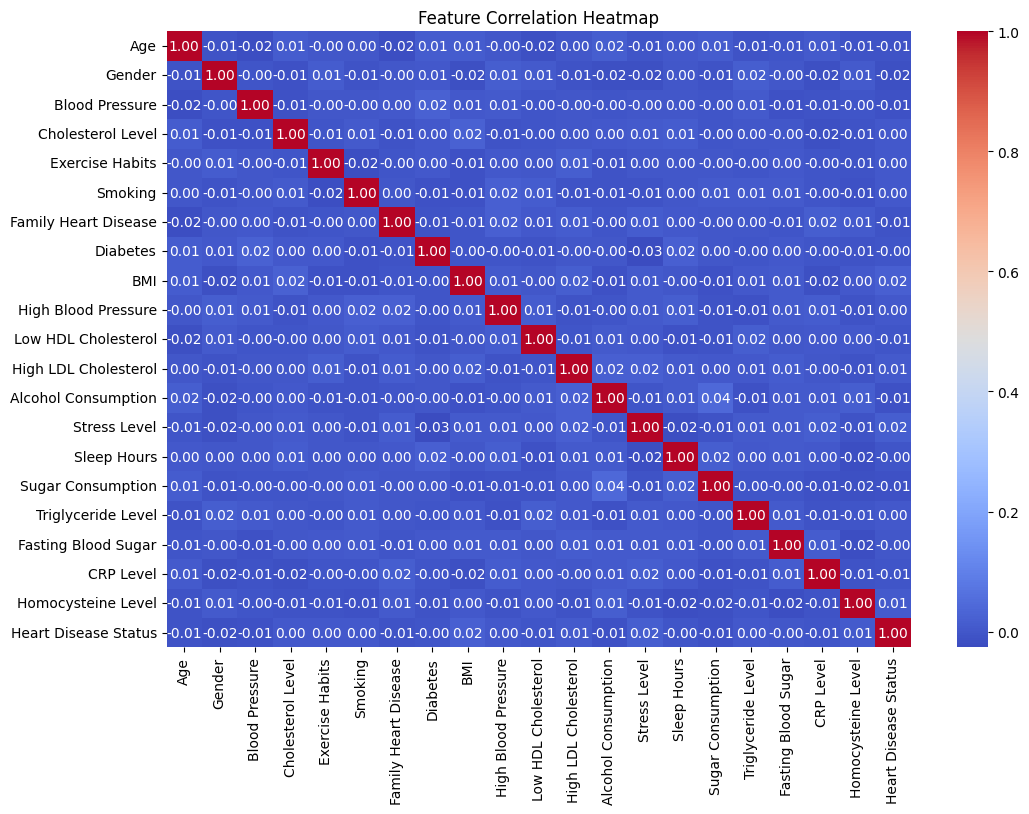

In [9]:
corr_matrix = data.corr()
plt.figure(figsize = (12, 8))
sns.heatmap(corr_matrix, annot = True, cmap = "coolwarm", fmt = ".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [10]:
scaler = MinMaxScaler()

X = data.drop(columns=['Heart Disease Status'])
data_scaled = scaler.fit_transform(X)
data_scaled = pd.DataFrame(data_scaled, columns=X.columns)
data_scaled['Heart Disease Status'] = data['Heart Disease Status']
data = data_scaled

In [11]:
joblib.dump(scaler, 'minmax_scaler.pkl')

['minmax_scaler.pkl']

In [12]:
X, y = data.drop(columns=['Heart Disease Status']), data['Heart Disease Status']

smote = SMOTE(sampling_strategy=1.0, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled,
    y_resampled,
    test_size=0.2,
    random_state=42
)

In [13]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=2,
    random_state=42
)
model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [14]:
joblib.dump(model, 'random_forest_model.pkl')

['random_forest_model.pkl']

In [15]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

In [16]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

         0.0       0.80      0.97      0.88      1604
         1.0       0.96      0.76      0.85      1596

    accuracy                           0.87      3200
   macro avg       0.88      0.87      0.86      3200
weighted avg       0.88      0.87      0.86      3200



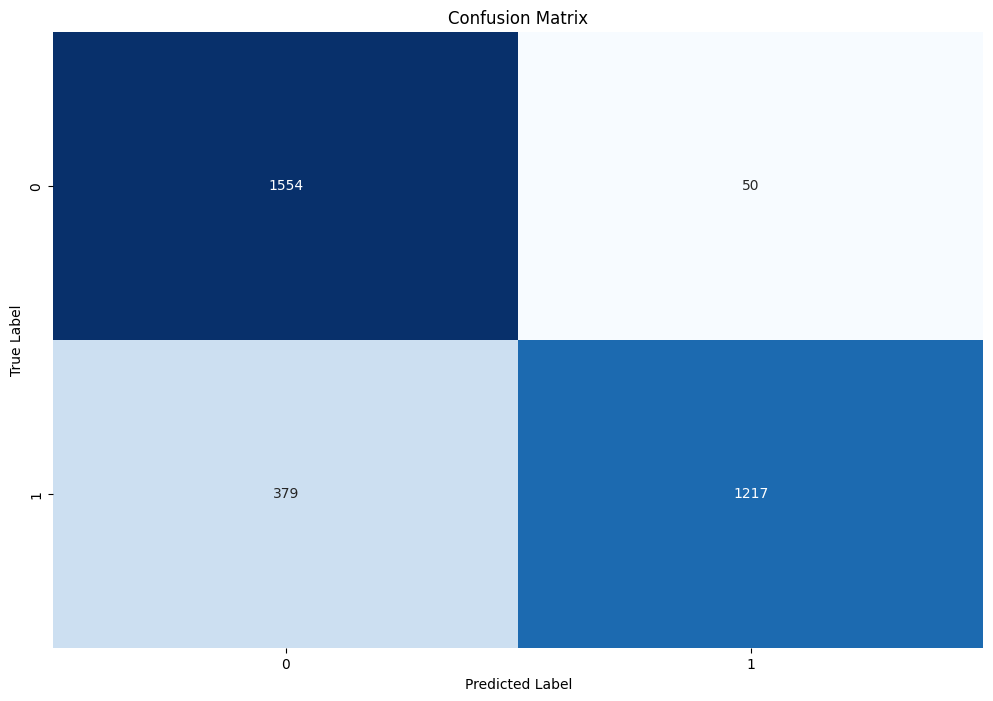

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize = (12, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

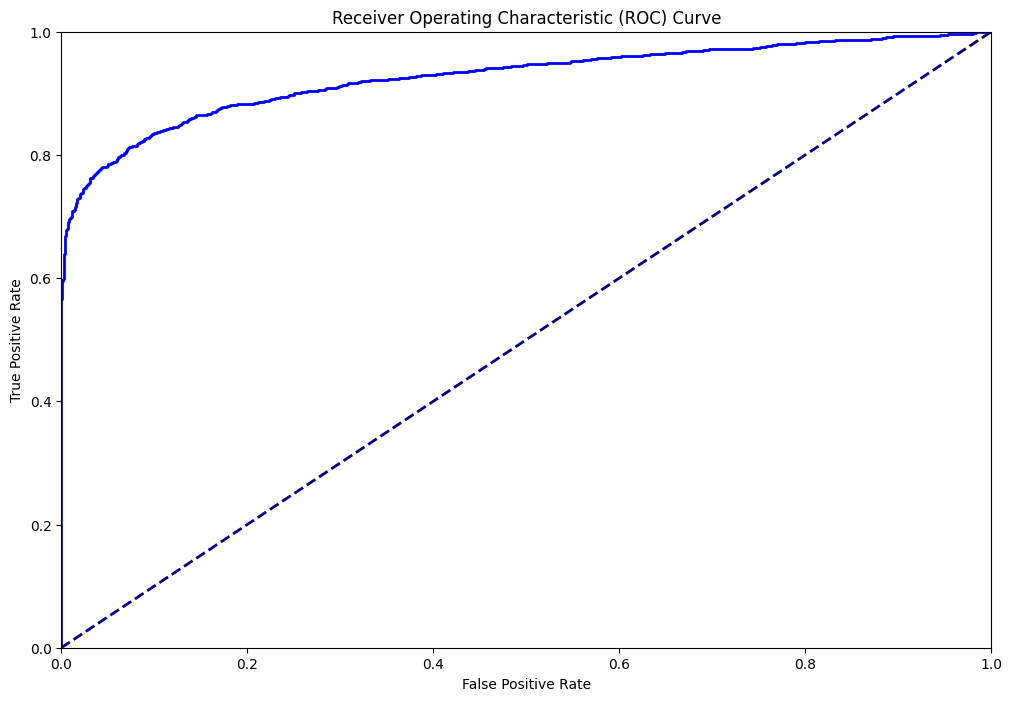

In [18]:
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

plt.figure(figsize = (12, 8))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.show()

In [19]:
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_proba)

print(f"Оптимальный порог: {thresholds[np.argmax(2 * (precision * recall) / (precision + recall + 1e-10))]:.2f}")

Оптимальный порог: 0.43
